# Deep Learning: Mastering Neural Networks - Module 4 Asignment: CNN Classification of FashionMNIST Dataset

Now that we have Convolutional layers in our deep learning toolkit, we are going tackle a new and more challenging dataset - the [FashionMNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist) dataset. This dataset is in a similar format to the MNIST dataset, however it contains images of different articles of clothing.

In this assignment, we ask that you develop a CNN classifier that implements **at least 2** convolutional layers.

A template has been provided below with some starter code and please feel free to reuse any code you have written or seen before in previous notebooks!



In [1]:
import torch
import torch.nn as nn
import numpy as np
import torchvision.datasets
from torchvision import transforms
from torch.utils.data import Subset
from torch.utils.data import DataLoader
from torch.nn.modules.flatten import Flatten
import time, copy
import matplotlib.pyplot as plt
import sklearn.metrics as metrics

# device config (train our model on GPU if it is available which is much faster)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
# These transforms will be performed on every datapoint - in this example we want to transform every
# datapoint to a Tensor datatype, and perform normalization
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize([0.5], [0.5])])

# Notice how FashionMNIST is also built into PyTorch!
fashion_mnist_train = torchvision.datasets.FashionMNIST('', train=True, transform =transform, download=True)

# We will split out train dataset into train and validation!
fashion_mnist_train, fashion_mnist_val = torch.utils.data.random_split(fashion_mnist_train, [int(np.floor(len(fashion_mnist_train)*0.75)), int(np.ceil(len(fashion_mnist_train)*0.25))])

fashion_mnist_test = torchvision.datasets.FashionMNIST('', train=False, transform = transform, download=True)

In [3]:
# We will create DataLoaders just like before with a batch size of 100
batch_size = 100
dataloaders = {'train': DataLoader(fashion_mnist_train, batch_size=batch_size),
               'val': DataLoader(fashion_mnist_val, batch_size=batch_size),
               'test': DataLoader(fashion_mnist_test, shuffle=True, batch_size=batch_size)}

dataset_sizes = {'train': len(fashion_mnist_train),
                 'val': len(fashion_mnist_val),
                 'test': len(fashion_mnist_test)}
print(f'dataset_sizes = {dataset_sizes}')

dataset_sizes = {'train': 45000, 'val': 15000, 'test': 10000}


## Visualization

Before we go any further, we want to visualize the different datapoints in our dataset. Similar to the MNIST datset, there are 10 different object classes and they map to the following labels:

* 0 - T-shirt/top
* 1 - Trouser
* 2 - Pullover
* 3 - Dress
* 4 - Coat
* 5 - Sandal
* 6 - Shirt
* 7 - Sneaker
* 8 - Bag
* 9 - Ankle boot

Using the function below, we can visualize some of the different images that we will be working with from each class. Additionally, follow this [link](https://www.kaggle.com/datasets/zalando-research/fashionmnist) to find more information on the dataset.

In [4]:
# plot a digit ground truth and autoencoding
def view_fashionmnist(label, count = 1):
    fig = plt.figure()
    idx = 1
    for inputs, labels in dataloaders["test"]:
        for i, input in enumerate(inputs):
            # we only want to view a certain class
            if (labels[i] != label):
                continue
            # plot the ground truth
            ax = fig.add_subplot(1, count, idx)
            input = input.cpu().detach().numpy().reshape((28,28))
            ax.imshow(input, cmap='gray')
            idx += 1
            if idx > count:
                break
        if idx > count:
            break

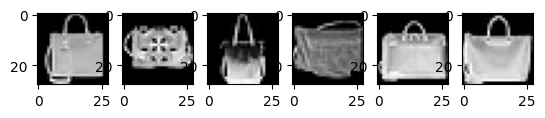

In [5]:
# View 6 bags
view_fashionmnist(8, 6)

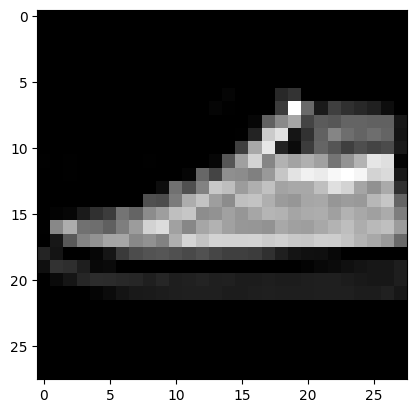

In [6]:
# View 1 sneaker
view_fashionmnist(7, 1)

## Your Turn

Use what you have learned so far to develop a CNN classifier that implements **at least 2** convolutional layers.

In [7]:
# Hint! Create a CNNClassifier class that implements a forward function

class CNNClassifier(nn.Module):
    def __init__(self, dropout=0.0):
        super(CNNClassifier, self).__init__()

        self.pipeline = nn.Sequential(
            # Conv block 1: (1, 28, 28) -> (16, 28, 28) -> pool -> (16, 14, 14)
            nn.Conv2d(in_channels = 1, out_channels = 16, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2),
            # Conv block 2: (16, 14, 14) -> (32, 14, 14) -> pool -> (32, 7, 7)
            nn.Conv2d(in_channels = 16, out_channels = 32, kernel_size = 3, stride = 1, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2),
            # Classifier head
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(32*7*7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 10)   # We have 10 clothing classes (raw logits for CrossEntropyLoss)
        )

    def forward(self, x):
        return self.pipeline(x)


In [8]:
learning_rate = 0.001
num_epochs = 10
model = CNNClassifier().to(device)

In [9]:
# Hint! Try reusing one of the training functions we have previously written
def train_classification_model(model, dataloaders, dataset_sizes, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict()) # keep the best weights stored separately
    best_acc = 0.0
    best_epoch = 0

    # Each epoch has a training, validation, and test phase
    phases = ['train', 'val', 'test']

    # Keep track of how loss and accuracy evolves during training
    training_curves = {}
    for phase in phases:
        training_curves[phase+'_loss'] = []
        training_curves[phase+'_acc'] = []

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        for phase in phases:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                # No need to flatten the inputs!
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # forward
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, predictions = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + update weights only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(predictions == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            training_curves[phase+'_loss'].append(epoch_loss)
            training_curves[phase+'_acc'].append(epoch_acc)

            print(f'{phase:5} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # deep copy the model if it's the best accuracy (bas
            if phase == 'val' and epoch_acc > best_acc:
              best_epoch = epoch
              best_acc = epoch_acc
              best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since
    print(f'\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f} at epoch {best_epoch}')

    # load best model weights
    model.load_state_dict(best_model_wts)

    return model, training_curves

In [10]:
# loss and optimizer
criterion = nn.CrossEntropyLoss() # CrossEntropyLoss for class
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)

# Make sure you save the training curves along the way for visualization afterwards!
model, training_curves = train_classification_model(model, dataloaders, dataset_sizes,
                                                    criterion, optimizer, scheduler,
                                                    num_epochs = num_epochs)


Epoch 1/10
----------
train Loss: 0.5614 Acc: 0.7947
val   Loss: 0.4065 Acc: 0.8527
test  Loss: 0.4156 Acc: 0.8479

Epoch 2/10
----------
train Loss: 0.3547 Acc: 0.8708
val   Loss: 0.3750 Acc: 0.8609
test  Loss: 0.3890 Acc: 0.8586

Epoch 3/10
----------
train Loss: 0.3056 Acc: 0.8901
val   Loss: 0.3393 Acc: 0.8741
test  Loss: 0.3560 Acc: 0.8715

Epoch 4/10
----------
train Loss: 0.2740 Acc: 0.9005
val   Loss: 0.3254 Acc: 0.8790
test  Loss: 0.3443 Acc: 0.8775

Epoch 5/10
----------
train Loss: 0.2497 Acc: 0.9096
val   Loss: 0.3144 Acc: 0.8837
test  Loss: 0.3341 Acc: 0.8823

Epoch 6/10
----------
train Loss: 0.2299 Acc: 0.9172
val   Loss: 0.3115 Acc: 0.8864
test  Loss: 0.3330 Acc: 0.8839

Epoch 7/10
----------
train Loss: 0.2126 Acc: 0.9227
val   Loss: 0.3035 Acc: 0.8915
test  Loss: 0.3257 Acc: 0.8858

Epoch 8/10
----------
train Loss: 0.1979 Acc: 0.9285
val   Loss: 0.2979 Acc: 0.8949
test  Loss: 0.3200 Acc: 0.8896

Epoch 9/10
----------
train Loss: 0.1835 Acc: 0.9338
val   Loss: 0.2939

### Visualizing Training Curves and Results

In [11]:
# Utility functions for plotting your results!
def plot_training_curves(training_curves,
                         phases=['train', 'val', 'test'],
                         metrics=['loss','acc']):
    epochs = list(range(len(training_curves['train_loss'])))
    for metric in metrics:
        plt.figure()
        plt.title(f'Training curves - {metric}')
        for phase in phases:
            key = phase+'_'+metric
            if key in training_curves:
                if metric == 'acc':
                    plt.plot(epochs, [item.detach().cpu() for item in training_curves[key]])
                else:
                    plt.plot(epochs, training_curves[key])
        plt.xlabel('epoch')
        plt.legend(labels=phases)

def classify_predictions(model, device, dataloader):
    model.eval()   # Set model to evaluate mode
    all_labels = torch.tensor([]).to(device)
    all_scores = torch.tensor([]).to(device)
    all_preds = torch.tensor([]).to(device)
    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = torch.softmax(model(inputs),dim=1)
        _, preds = torch.max(outputs, 1)
        scores = outputs[:,1]
        all_labels = torch.cat((all_labels, labels), 0)
        all_scores = torch.cat((all_scores, scores), 0)
        all_preds = torch.cat((all_preds, preds), 0)
    return all_preds.detach().cpu(), all_labels.detach().cpu(), all_scores.detach().cpu()

def plot_cm(model, device, dataloaders, phase='test'):
    class_labels = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
    preds, labels, scores = classify_predictions(model, device, dataloaders[phase])

    cm = metrics.confusion_matrix(labels, preds)
    disp = metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    ax = disp.plot().ax_
    ax.set_title('Confusion Matrix -- counts')


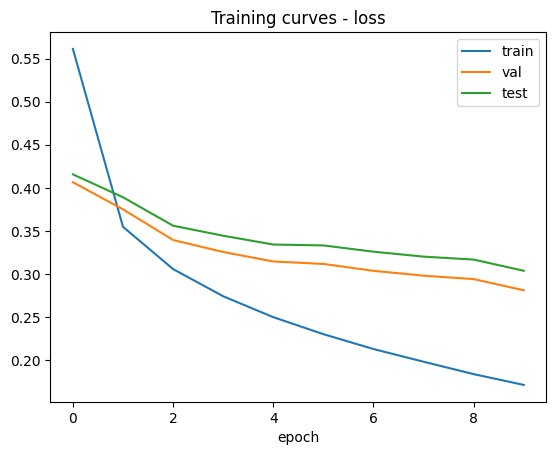

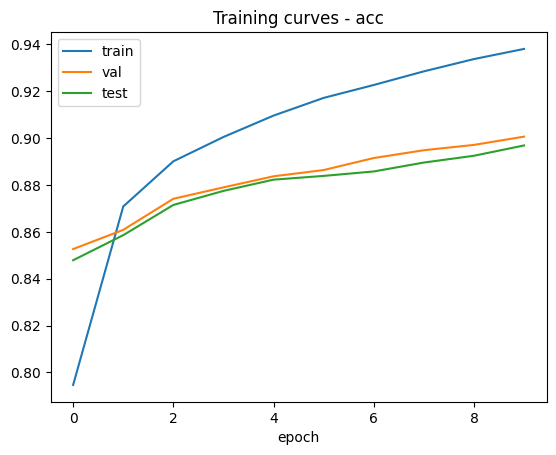

In [12]:
plot_training_curves(training_curves, phases=['train', 'val', 'test'])

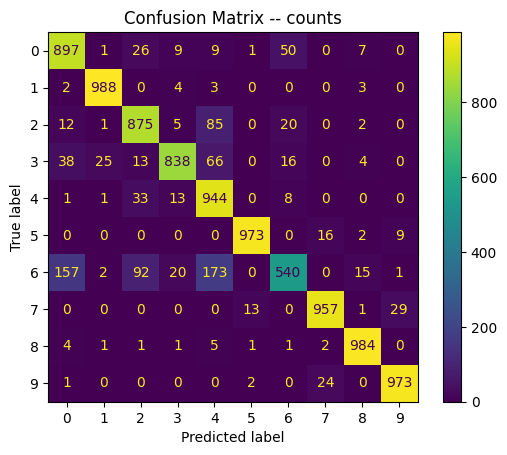

In [13]:
res = plot_cm(model, device, dataloaders, phase='test')

## Conclusions

Now that we have implemented our network we want to examine the results.

What class of object is most often misclassified? What class is it incorrectly classified as most often?

Additionally, try re-training your network with dropout included. Does this help the performance or is there a noticeable change in the ability of the model to generalize? Is the most commonly misclassified object still the same as with no dropout?

Response:

 Most misclassified class: Shirt (6) is the most frequently misclassified class. Without dropout, 238 of 1,000 shirts were wrong. They were most often predicted as T-shirt/top (0) (94 times), followed by Coat (4) (79) and Pullover (2) (33). This makes sense: at 28×28 grayscale, these upper-body garments have very similar silhouettes.

 Most misclassified class with dropout: It's still Shirt (6), and the problem got worse: only 664 were correct, and 126 were predicted as T-shirt/top. Dropout made the model generalize better overall but didn't help it tell apart the most visually similar classes.


In [14]:
# Re-training with dropout
model_dropout = CNNClassifier(dropout=0.3).to(device)
print(model_dropout)

optimizer = torch.optim.Adam(model_dropout.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.95)

model_dropout, training_curves_dropout = train_classification_model(model_dropout, dataloaders, dataset_sizes,
                                                                     criterion, optimizer, scheduler,
                                                                     num_epochs=num_epochs)

CNNClassifier(
  (pipeline): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=1568, out_features=128, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.3, inplace=False)
    (11): Linear(in_features=128, out_features=10, bias=True)
  )
)

Epoch 1/10
----------
train Loss: 0.6284 Acc: 0.7705
val   Loss: 0.4332 Acc: 0.8369
test  Loss: 0.4459 Acc: 0.8280

Epoch 2/10
----------
train Loss: 0.4112 Acc: 0.8490
val   Loss: 0.3456 Acc: 0.8741
test  Loss: 0.3599 Acc: 0.8676

Epoch 3/10
----------
train Loss: 0.3601 Acc: 0.8685
val   Loss: 0.3127 Acc: 0.8858
test  Loss: 0.3271 Acc: 0

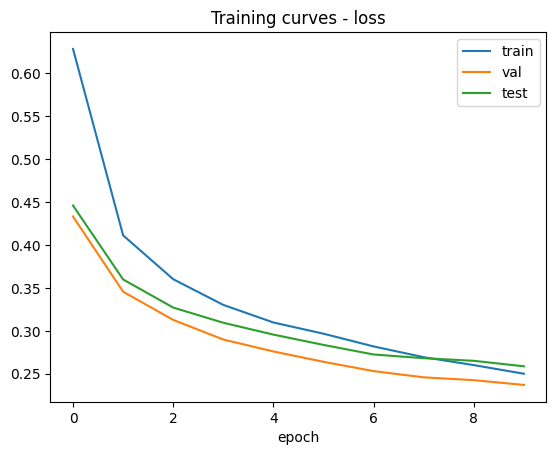

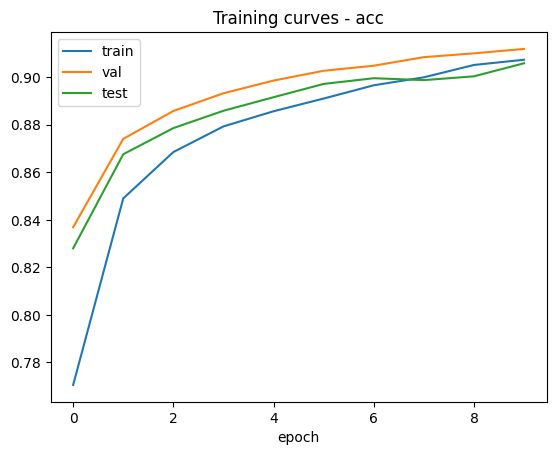

In [15]:
plot_training_curves(training_curves_dropout, phases=['train', 'val', 'test'])

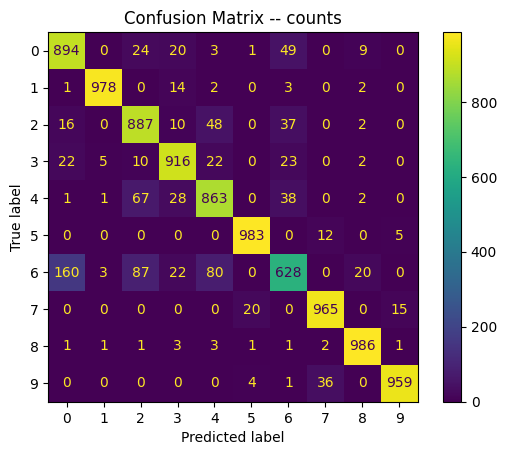

In [16]:
res_dropout = plot_cm(model_dropout, device, dataloaders, phase='test')